# Violation Types and Risk Indicators in Ex-Ante Financial Control

### An analysis of the reports of the Public Financial Inspection Agency on schools under procedure BG-RRP-1.015 of the National Recovery and Resilience Plan

**An indicator is not a proven violation.** The findings and administrative violation acts of the Public Financial Inspection Agency (Bulgarian: *Агенция за държавна финансова инспекция*, ADFI) are formal administrative indicators. They remain subject to administrative-penal and judicial review under Bulgarian law. No school, municipality or person is accused of anything in this study.

**Abbreviations.** ADFI is the Public Financial Inspection Agency. NRRP is the National Recovery and Resilience Plan (in Bulgarian НПВУ). `FID1`–`FID7` are English working abbreviations of the seven Inspection Activity Directorates of the ADFI (`ДИД1`–`ДИД7`, *Дирекция „Инспекционна дейност“ 1–7*).

Author: Valeriy Beluhov.

## Introduction

### Significance

Before a public body commits money, the law requires a check that the commitment is lawful: this is *ex-ante* (preliminary) financial control. Under the Financial Management and Control in the Public Sector Act (Bulgaria, 2006a) the control is carried out by the finance staff of the body and is documented by a signature. When the ADFI inspects a school afterwards (Bulgaria, 2006b), its report shows where the control and the procurement rules were not respected.

A controller who reads such a report usually works with the **article that was breached**. The article is a poor guide to what went wrong: the same article is breached by acts that differ a great deal in practice, and one practical failure is often assessed under several articles. This study therefore sorts the findings by the **type of the violation**, that is, by *what the contracting authority did or failed to do* (for example, splitting one procurement into parts, or awarding directly a contract whose value requires a call). Types make findings countable, comparable between inspectors and usable as risk indicators: a type that recurs is a candidate for a control point in advance.

### The author's previous study and what is done here

The data come from procedure BG-RRP-1.015 "School STEM Environment" under the National Recovery and Resilience Plan (NRRP; in Bulgarian НПВУ). The author's earlier study, Beluhov (2026), *Fiscal Exposure and Integrity Risk in School Public Procurement: Forensic Econometric and Network Analysis of the Bulgarian School STEM Programme (BG-RRP-1.015)* (repository `stem-collusion-npvu`), screens the whole programme and validates its indicators against 560 inspection reports of the ADFI (ADFI, 2026). The classification of the findings of those reports into types is the author's: it was prepared from the text of the reports by rule-based text classification, and that study checks it. **This notebook does not repeat the screening of the programme.** It takes the 560 reports and the classification as its object and does five things, one in each part of the study:

1. describes and verifies the database of the reports and defines the classifier;
2. measures how the findings are spread over the types;
3. tests whether the same type of action is recorded as a violation equally often in all seven directorates;
4. separates the findings on ex-ante control from the findings on the procurement rules;
5. checks whether the type of a finding can be predicted from the text of the report.

## Theoretical background

**Legal framework.** The reports state findings under the Public Procurement Act (Bulgaria, 2016), under the Financial Management and Control in the Public Sector Act (Bulgaria, 2006a), and under the Public Financial Inspection Act (Bulgaria, 2006b), which governs the inspections and the acts of the ADFI. Classifier section 10 isolates the findings on ex-ante control and the double signature that Bulgaria (2006a) requires from the other findings.

**Classification by action.** A finding is classified by the action of the contracting authority, not by the article of the law. The class is therefore a *type of violation*; the article is kept only as an attribute.

**Statistical methods that later stages of the study use.** The tools are listed here so that the hypotheses of Section 1.2 can be read with their method. The glossary in Section 1.2.2 gives every formula.

| Method | Used for | Source |
|---|---|---|
| Pearson chi-squared statistic | difference between observed and expected counts | Pearson (1900) |
| Permutation test with the exact p-value correction | p-value without an assumption on the distribution | Phipson and Smyth (2010) |
| Benjamini–Hochberg false discovery rate | many classes tested at once | Benjamini and Hochberg (1995) |
| Cramér's V | size of the difference, independent of the sample size | Cramér (1946) |
| Wilson interval | uncertainty of a share | Wilson (1927) |
| Cohen's kappa | agreement between two classifications | Cohen (1960) |
| Cluster bootstrap | uncertainty when findings of one report are not independent | Efron and Tibshirani (1994) |
| TF-IDF weighting | text features for the prediction of the type | Salton and Buckley (1988) |
| Scikit-learn implementation | grouped cross-validation, logistic regression | Pedregosa et al. (2011) |

**Assumptions of the author.** The thresholds of the hypotheses (10 of 53 classes, 80 %, 10 units per outcome, α = 0.05) are the author's convention. They were fixed before any computation and are not derived from the literature.

## 1. Purpose and Hypotheses

### (1) Research Question

#### 1.1.1 Object of the study and the classification

**Object.** The object of the study is the set of 560 reports of the Public Financial Inspection Agency (ADFI) on schools that received funds under procedure BG-RRP-1.015 "School STEM Environment" of the National Recovery and Resilience Plan (NRRP). The reports were published from August 2024 to October 2026. Each report assesses a number of requirements of the procurement rules and of financial management and control, and records for each requirement either a violation or that the requirement was met.

**Premises.**

1. A report is made of **findings**; a finding is one assessed requirement and has one outcome.
2. The ADFI establishes the violation and issues the administrative violation act. The study does not re-assess any finding.
3. A finding is classified by the **action of the contracting authority** and not by the article of the law, because the same article is breached by acts that differ a great deal in practice.
4. The classification is the author's. It is described below and fetched, in its tabular form, in Section 2.2.7.

**The classification.** The classifier has 11 sections and 53 classes. The sections and the classes of each section are:

- **1. Selection of Award Procedure** – Splitting of procurements; Direct award at a value requiring a call or procedure; Invitation to specific persons or direct negotiation without legal basis; Negotiation without evidence sent to PPA Agency; Works awarded directly without a written contract; Estimated value determined without up-to-date market research
- **2. Subject Matter and Technical Specification** – Market consultations without disclosure; Heterogeneous supplies in a procurement without lots; Heterogeneous supplies in a single lot of a divided procurement; Tailored specifications – brand or model specified; Omitted environmental requirements for products; Standard required for the supplied goods
- **3. Requirements for Tenderers** – Requirement for own service base or support system; Information security or service management certificate required from the tenderer in a supply procurement (ISO/IEC 27001, 27701, 20000-1); Quality, environmental, or occupational health and safety certificate required from the tenderer (ISO 9001, 14001, 45001); Requirements for the tenderer's team; Requirement for experience in similar activities; Turnover requirement; Requirement for manufacturer authorization; Requirement for registration that is not due or is excessive; EcoVadis sustainability rating required from the tenderer; Requirement for training by an organization with a minister-approved program; Narrowed evidence for a selection criterion
- **4. Tender Submission and Evaluation** – Requirements for the content of the technical proposal (work program, strategy, risk management approach) as a condition for admission; Unlawful evaluation methodology; Maximum unit prices as a condition for admission; Declaration under Art. 47(3) PPA required with the tender; Design or visualization of the goods required with the tender
- **5. Launching the Procurement** – Incomplete contract notice or call; Unlawfully determined guarantees in the contract notice or draft contract; Change of opening date without notice; Contract duration over 5 years without reasons; Tender submission deadline on a non-working day
- **6. Evaluation Committee Work** – Appointment and composition of the committee; conflict-of-interest declaration not submitted on time; Admission, evaluation, or ranking in deviation from the conditions
- **7. Contract Conclusion** – Contract concluded without documents or without a fulfilled condition; Contract different from the draft and from the tender; Contract concluded before entry into force of the launch decision
- **8. Contract Performance** – Contract modification without legal basis
- **9. Publicity and Procurement Dossier** – Award notice not sent on time in a procedure; Award notice not sent on time in a call for tenders; Contract completion or modification notice not sent on time; Contract or annex not published on time; Committee protocols and reports not published on time; Decision, contract notice or call, documentation, invitations, or clarifications not published on time; Incomplete procurement dossier
- **10. Financial Management and Control** – Commitment or payment without ex-ante control; Commitment or payment without double signature; Unestablished procedure for ex-ante control; Unperformed ex-ante control for legality of a procurement above the threshold
- **11. Breaches of Other Statutes in Procurement Checks** – Upcoming payment notification not sent on time via IS Public Payments; Payment without confirmation from NRA and Customs Agency; Concluded contract notification not sent on time via IS Public Payments

The classes are defined as data in Section 2.2.7, where the findings of the 560 reports are counted by class.

The questions below are asked before any result is shown. Their answers are given in the part of the study that tests the hypotheses.

#### 1.1.2 Question 1 – how are the findings spread over the types of violation?

**Why it matters for a controller.** A control body has limited time. If the findings were spread evenly over many types, no control point would be worth more than another. If a few types accounted for most of the findings, a control point placed on those types would cover most of what the inspections find. The question asks which of the two cases the inspection reports show, and it asks it about *types of action*, not about articles of the law.

**Method.** Let $v_k$ be the number of violation rows in class $k$ ($k=1,\dots,K$ with $K=53$), and

$$ s_k=\frac{v_k}{\sum_{j=1}^{K} v_j},\qquad C(m)=\sum_{i=1}^{m} s_{(i)}, $$

where $s_{(1)}\ge s_{(2)}\ge\dots$ are the shares in descending order. $C(m)$ is the share of all violation rows that the $m$ most frequent classes carry.

**H1a (concentration).** *At most 10 of the 53 classes carry at least 80 % of all violation rows*, that is, $C(10)\ge 0.80$.

The numbers 10 of 53 and 80 % are a convention of the author, set before the computation. They name a level of concentration at which a control point on a handful of types would be practical; they are not a statistical law.

#### 1.1.3 Question 2 – is the same type of action recorded as a violation equally often in all directorates?

**Why it matters for a controller.** The seven directorates inspect different schools. If the share of findings of one type differs between directorates, the reason may be a different practice of the schools, a different composition of the inspected procurements, or a different reading of the same text by the inspectors. The data cannot tell these apart. A difference is therefore an **indicator** that deserves a look, not a verdict on a directorate.

**Logic of the test (for readers without statistics).** For one class, each unit (one report × class) ends either in a violation or in no violation. Suppose that the directorate has *no influence* on the outcome. This is the **null model**. Then the labels "FID1…FID7" could be shuffled over the units without changing anything. We shuffle them 10,000 times, measure each time how far the table is from "no influence", and count how often chance alone gives a distance as large as the one observed. That share is the **p-value**: it answers "what would chance give?". A small p-value means that chance rarely gives so large a difference.

**Method.** For one class with $r$ directorates and $c=2$ outcomes, the observed counts are $O_{ij}$, the row totals $n_{i\cdot}$, the column totals $n_{\cdot j}$ and the number of units $N$. Under the null model the expected counts are $E_{ij}=n_{i\cdot}n_{\cdot j}/N$, and

$$ \chi^2=\sum_{i,j}\frac{(O_{ij}-E_{ij})^2}{E_{ij}},\qquad p=\frac{1+\#\{\chi^{2*}\ge\chi^2_{\text{obs}}\}}{R+1},\quad R=10{,}000, $$

where $\chi^{2*}$ is the statistic after one random shuffle of the directorate labels (Pearson, 1900; Phipson and Smyth, 2010). With $m$ eligible classes tested together, the p-values are adjusted by the Benjamini–Hochberg procedure (Benjamini and Hochberg, 1995):

$$ q_{(i)}=\min_{j\ge i}\ \frac{m}{j}\,p_{(j)}, $$

and the size of a difference is given by Cramér's V (Cramér, 1946): $V=\sqrt{\chi^2/\bigl(N\min(r-1,\,c-1)\bigr)}$.

**H1b (heterogeneity between directorates).** *The share of violations differs between the directorates `FID1`–`FID7` in at least one eligible class*: a class is **eligible** if it has at least 10 units in each of the two outcomes, and H1b holds if $q<0.05$ for at least one eligible class.

**Limit.** The test does not separate a different practice of the schools, a different composition of the inspected procurements and a different reading of the text. For that reason a significant result is an indicator and not a finding against a directorate.

### (2) Methodological Design and Decision Rules Fixed Before Computation

#### 1.2.1 Hypotheses and decision rules

The hypotheses and their thresholds were fixed before any result was computed. The thresholds are the author's convention (see the Theoretical background), not a result.

| Hypothesis | Statement | Decision rule |
|---|---|---|
| **H1a** (concentration) | at most 10 of the 53 classes carry at least 80 % of all violation rows | $C(10)\ge 0.80$ |
| **H1b** (heterogeneity) | the share of violations differs between `FID1`–`FID7` in at least one eligible class | eligible class: at least 10 units in each outcome; $q<0.05$ (Benjamini–Hochberg) after 10,000 permutations |

Later stages of the study use 2,000 bootstrap replications, a manual sample of 150 unique findings and 5 folds of grouped cross-validation; they are fixed here for the same reason.

**Three complementary checks of the classification** (later stages of the study):

1. an independent rule baseline of keywords and citations, evaluated without reading the quoted legal basis of the finding;
2. a stratified blind manual annotation of 150 unique findings;
3. a supervised model, TF-IDF with one-vs-rest logistic regression, evaluated by 5-fold cross-validation grouped by `report_key`.

#### 1.2.2 Glossary for controllers, with formulas

| Term | Meaning | Formula |
|---|---|---|
| **Report** | one inspection report of the ADFI | key `YYYY/MM/stem` (Section 2.2.2) |
| **Finding** | one assessed requirement in a report, with one number `finding_no`: either a violation or an assessment of no violation | $N_{\text{findings}}=\lvert\{\text{finding\_no}\}_{\text{viol}}\rvert+\lvert\{\text{finding\_no}\}_{\text{noviol}}\rvert$ |
| **Row (finding × class)** | one finding in one class of the classifier; a finding with several classes has several rows | $N_{\text{rows}}=N_{\text{viol\_rows}}+N_{\text{noviol\_rows}}$ |
| **Class** | the type of the action; 53 classes | index `section.class`, e.g. `1.02` |
| **Section** | group of classes; 11 sections | – |
| **Outcome** | `violation_with_act`, `violation_without_act` or `no_violation` | – |
| **Act** | administrative violation act issued by the ADFI | – |
| **Share of a class** | part of all violation rows that belongs to the class | $s_k=v_k/\sum_j v_j$ |
| **Cumulative share** | share carried by the $m$ most frequent classes | $C(m)=\sum_{i=1}^{m}s_{(i)}$ |
| **Contingency table** | counts of units by directorate and outcome | $O_{ij}$ |
| **Expected count** | count under "the directorate has no influence" | $E_{ij}=n_{i\cdot}n_{\cdot j}/N$ |
| **Chi-squared statistic** | distance of the table from the expected one | $\chi^2=\sum (O_{ij}-E_{ij})^2/E_{ij}$ |
| **Permutation p-value** | how often shuffled labels are at least as far from "no influence" | $p=(1+\#\{\chi^{2*}\ge\chi^2_{\text{obs}}\})/(R+1)$ |
| **False discovery rate, q-value** | adjusted p-value when many classes are tested | $q_{(i)}=\min_{j\ge i}(m/j)\,p_{(j)}$ |
| **Cramér's V** | size of a difference between 0 and 1 | $V=\sqrt{\chi^2/(N\min(r-1,c-1))}$ |
| **Wilson interval** | interval for a share $\hat p$ from $n$ units, $z=1.96$ | $\dfrac{\hat p+\frac{z^2}{2n}\pm z\sqrt{\frac{\hat p(1-\hat p)}{n}+\frac{z^2}{4n^2}}}{1+z^2/n}$ |
| **Cohen's kappa** | agreement of two classifications beyond chance | $\kappa=\dfrac{p_o-p_e}{1-p_e}$ |
| **Cluster bootstrap** | resample whole reports ($B=2000$) to get the spread of a statistic | percentile interval of $B$ resampled values |
| **TF-IDF** | weight of a word in a report | $\text{idf}(t)=\ln\dfrac{1+N}{1+\text{df}(t)}+1$ |
| **Grouped cross-validation** | train and test on different reports (5 folds) | `GroupKFold(5)` |
| **EGN checksum** | validity test of a ten-digit personal number; used only to find personal data | $\bigl(\sum_{i=1}^{9}w_i d_i\bigr) \bmod 11$, $w=(2,4,8,5,10,9,7,3,6)$; a result of 10 counts as 0 |
| **Indicator** | a signal for attention | not a proven violation |

### (3) Scope and Guardrails

#### 1.3.1 Scope

The study covers the **560 reports** published from August 2024 to October 2026 and listed in the register of the reports (ADFI, 2026). The number is the control against a missed report: the notebook checks it in the table of the metadata and in the classification table (Section 2.2.9); the check against the register and the texts of the reports was made when the data were prepared (Section 2.2.4).

**Guardrails.** An indicator is not a proven violation, and no school, municipality or person is accused of anything. The study works only with the texts of the reports. The reports are public and are cited; their texts are not reproduced in this repository, and only counts of suspicious patterns are kept (Section 2.2.3).

#### 1.3.2 Environment and configuration

**What the next cell does.** It imports the packages used here, checks their versions against `requirements.txt` (pinned with `==`), defines the paths and the constants of the study and sets one style for all figures. The packages of later stages (scikit-learn, statsmodels) are listed in `requirements.txt` but are not used here, so only the packages used here are shown and checked.

In [1]:
import csv
import hashlib
import importlib.metadata as md_meta
import json
import pathlib
import re
import textwrap
import urllib.request

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = pathlib.Path.cwd()
DATA_DIR = ROOT / "data"
DERIVED_DIR = DATA_DIR / "derived"
FIG_DIR = ROOT / "fig"
for _d in (DERIVED_DIR, FIG_DIR):
    _d.mkdir(parents=True, exist_ok=True)

_pinned = {}
for _line in (ROOT / "requirements.txt").read_text(encoding="utf-8").splitlines():
    if "==" in _line:
        _name, _ver = _line.strip().split("==")
        _pinned[_name.lower()] = _ver
_rows = []
for _name in ("pandas", "numpy", "matplotlib"):
    try:
        _have = md_meta.version(_name)
    except md_meta.PackageNotFoundError:
        _have = "not installed"
    _rows.append((_name, _pinned[_name], _have, _have == _pinned[_name]))
VERSIONS = pd.DataFrame(_rows, columns=["package", "pinned", "installed", "match"])
display(VERSIONS)
assert VERSIONS["match"].all(), "Installed versions differ from requirements.txt"

HYPOTHESIS_THRESHOLDS = {
    "H1a_max_classes": 10,
    "H1a_min_cum_share": 0.80,
    "H1b_min_units_per_outcome": 10,
    "H1b_permutations": 10000,
    "H1b_fdr_alpha": 0.05,
    "bootstrap_replications": 2000,
    "manual_sample_n": 150,
    "kfold_splits": 5,
}
print("Thresholds fixed before computation:", json.dumps(HYPOTHESIS_THRESHOLDS))

REF_REPO = "beluhov/stem-collusion-npvu"
REF_COMMIT = "c5feef1"
REF_PATH = "data/adfi_classification.csv"
REF_URL = f"https://raw.githubusercontent.com/{REF_REPO}/{REF_COMMIT}/{REF_PATH}"
BUILD_DATE = "2026-11-17"

C_BLUE, C_ORANGE, C_GREEN, C_VERMILION, C_GREY = "#0072B2", "#E69F00", "#009E73", "#D55E00", "#6B6B6B"
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 300, "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
    "axes.axisbelow": True, "figure.facecolor": "white", "axes.facecolor": "white",
})
print(f"Environment ready | matplotlib {matplotlib.__version__} | figures: {FIG_DIR.name}/ at 300 dpi")

,package,pinned,installed,match
0,pandas,3.1.0,3.1.0,True
1,numpy,2.5.4,2.5.4,True
2,matplotlib,3.11.2,3.11.2,True


Thresholds fixed before computation: {"H1a_max_classes": 10, "H1a_min_cum_share": 0.8, "H1b_min_units_per_outcome": 10, "H1b_permutations": 10000, "H1b_fdr_alpha": 0.05, "bootstrap_replications": 2000, "manual_sample_n": 150, "kfold_splits": 5}
Environment ready | matplotlib 3.11.2 | figures: fig/ at 300 dpi


## 2. Data and Reconciliation

### (1) Question Addressed

**Question.** Do the register of the reports, the 560 reports and the classification table describe the same reports? Every link between them was checked when the data were prepared and is asserted again on the tables.

### (2) Method: Relational Key Normalization and Pattern-Based PII Audit

#### 2.2.1 Sources

1. **Register of the reports** (ADFI, 2026): one row per published report with the school (with its settlement and, where the register gives them, the municipality and the region), the date of publication and the designation of the report. The register is the public list of the ADFI of inspections under Art. 17 of the Public Financial Inspection Act (Bulgaria, 2006b).
2. **The 560 reports from (ADFI, 2026)**, year of publication (2024, 2025, 2026).
3. **The classification table** of the findings, fetched in Section 2.2.7 from the author's earlier study (Beluhov, 2026).

The register of the reports and the reports are public information and are cited. The first and second sources are not included in this repository. Section 2.2.4 describes how each was processed, with the results of the processing, and the tables built from them are in `data/` and `data/derived/`. The notebook runs from these tables.

#### 2.2.2 The report key

A report is identified by the key `YYYY/MM/stem`. The classification table writes the path of some reports in a notation that differs from the key, so every path is brought to one form: the differences in the notation of the path (a leading word, the extension, repeated dots and a trailing `pdf`) are removed. The function is applied to the whole classification table in Section 2.2.9.

**What the next cell does.** It defines two helper functions: `sha256_file` computes the SHA-256 digest of a file, and `normalize_report_key` brings a path to the key.

In [2]:
def sha256_file(path: pathlib.Path) -> str:
    """Compute SHA-256 hex digest of a file."""
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(65536), b""):
            h.update(chunk)
    return h.hexdigest()


def normalize_report_key(rel_path: str) -> str:
    """Normalize a report path to the canonical YYYY/MM/stem key."""
    p = rel_path.replace("\\", "/").strip()
    parts = p.split("/")
    fn = parts[-1]
    if fn.startswith("Доклад "):
        fn = fn[len("Доклад "):]
    fn = re.sub(r"\.+md$", "", fn, flags=re.IGNORECASE)
    fn = re.sub(r"\.+pdf$", "", fn, flags=re.IGNORECASE)
    fn = re.sub(r"pdf$", "", fn, flags=re.IGNORECASE)
    parts[-1] = fn
    return "/".join(parts)

#### 2.2.3 Search for personal data

The texts are public, but they may mention persons. The study therefore does not publish the texts and stores **only counts** of suspicious patterns per report, never the matched strings. Five patterns are counted: an e-mail address, a telephone number, an explicit label `ЕГН` followed by ten digits, any ten-digit number that passes the checksum of the Bulgarian personal number, and two capitalised words after a role noun (such as *директор*).

**The checksum.** For a ten-digit string $d_1\dots d_{10}$ the first nine digits are weighted with $w=(2,4,8,5,10,9,7,3,6)$:

$$ r=\Bigl(\sum_{i=1}^{9} w_i d_i\Bigr)\bmod 11,\qquad c=\begin{cases} r & r<10\\ 0 & r=10\end{cases}, $$

and the string is a candidate only if $c=d_{10}$ and the first six digits are a valid date.

**The date rule.** The first six digits must form a real date: the month is 01–12 for the years 1900–1999, 21–32 for 1800–1899 and 41–52 for 2000–2099; the day must exist in that month, with February 29 allowed only in a leap year.

**The patterns.** The five counts per report are made by these rules:

- *e-mail address*: a local part, the sign `@`, a domain and an ending of at least two letters;
- *telephone number*: a mobile number that starts with `+359` or `0` and continues with 87, 88 or 89 and seven digits, in groups separated by a space or a hyphen, or the abbreviation `тел.` followed by a number of 7 to 14 digits;
- *explicit label*: the label `ЕГН` (or its Latin form) followed by ten digits;
- *checksum candidate*: any ten-digit number that passes the date rule and the checksum above;
- *name after a role noun*: one of the nouns director, chair, member, financial inspector, legal adviser, chief accountant or financial controller, optionally followed by `на` and up to 35 characters of the body, and then two or three words that begin with a capital letter.

**What was done.** The five counts were computed for the text of each of the 560 reports when the data were prepared. The matched strings were not stored. The result is the table `data/derived/pii_scan.csv` with the columns `report_key`, `pattern_type` and `match_count`, one row for each report and pattern with at least one hit (678 rows). The table is read in Section 2.2.4 and drawn in Figure 3.

#### 2.2.4 Construction of the report metadata

**What was done.** The register of the reports and the 560 reports were read once, when the data were prepared. The result is two tables: the metadata of each report and the counts of candidate personal data. For each report:

- the report key was computed and the register row with the same key was looked for;
- the directorate was read from the report designation (`ДИД1`–`ДИД7`) and given its working label `FID1`–`FID7`;
- the characters, the lines and the headings were counted, and the SHA-256 of the text was computed;
- the five counts of Section 2.2.3 were computed on the text and only the counts were kept, never the matched strings.

Two checks had to pass: the register held 560 distinct keys, and the 560 reports matched them one to one. The result is 560 rows with 20 columns and 678 rows of personal-data counts.

**The columns of the metadata table.**

| Column | Content |
|---|---|
| `report_id` | number of the report in the register |
| `report_key` | the key `YYYY/MM/stem` (Section 2.2.2) |
| `year`, `month` | year and month of publication |
| `directorate_bg`, `directorate_en` | the directorate from the report designation (`ДИД1`–`ДИД7`) and its working label (`FID1`–`FID7`) |
| `region_code` | the two letters that follow the directorate in the report designation |
| `report_seq_num` | the number in the report designation |
| `published_date` | date of publication in the register |
| `school`, `school_type` | the school as the register names it, with its settlement, and its type |
| `locality`, `municipality`, `province` | the settlement, the municipality and the region as the register gives them; empty where the register does not give them |
| `inspection_basis` | the legal basis of the inspection, as the register gives it |
| `char_count`, `line_count`, `heading_count` | the number of characters, lines and headings of the text of the report |
| `text_sha256` | the SHA-256 digest of the text of the report |
| `eik` | the nine-digit identifier (EIK) of the school |

**What the next cell does.** It reads the two tables from `data/` and `data/derived/` and asserts the same totals: 560 reports, 20 columns, a unique report key and a nine-digit identifier of the school for every report. The next sections use these tables.

In [3]:
META_COLUMNS = 20
meta_df = pd.read_csv(DATA_DIR / "adfi_reports_meta.csv", sep=";", encoding="utf-8", dtype=str)
pii_df = pd.read_csv(DERIVED_DIR / "pii_scan.csv", sep=";", encoding="utf-8")
assert len(meta_df) == 560 and meta_df.shape[1] == META_COLUMNS
assert meta_df["report_key"].is_unique
assert meta_df["eik"].str.fullmatch(r"\d{9}").all()
print(f"Reports: {len(meta_df)} | columns: {meta_df.shape[1]} | PII hit rows: {len(pii_df)}")

Reports: 560 | columns: 20 | PII hit rows: 678


#### 2.2.5 Coverage by month and by directorate

**Question.** In which months were reports published, and how many came from each directorate?

**Logic.** The count of reports per month shows the period that the study covers and its gaps. A month with zero reports means that the sample contains no report for that month. The count per directorate shows how the 560 reports are divided between `FID1`–`FID7`; it describes the data and is not a test.

**What the next cell does.** It counts the reports by month of publication (August 2024 to October 2026), asserts the totals by year, and draws Figure 1 with the numbers of reports above the bars.

,0,1,2,3,4,5,6,7,8,9,...,17,18,19,20,21,22,23,24,25,26
month,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,...,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
reports,7,0,2,3,5,1,4,9,19,10,...,34,36,43,36,19,28,42,33,36,19


Months in the period: 27 | months without a report: 1


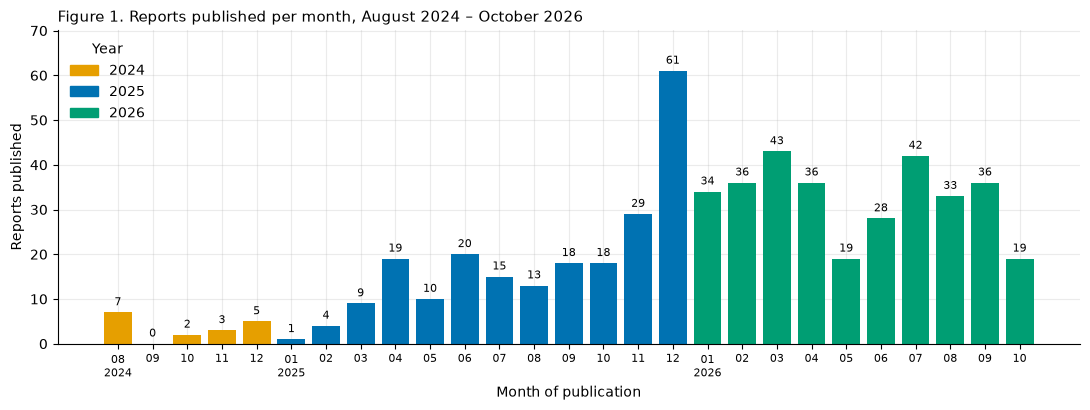

In [4]:
months = pd.period_range("2024-08", "2026-10", freq="M")
meta_df["period"] = pd.PeriodIndex(meta_df["year"] + "-" + meta_df["month"], freq="M")
by_month = meta_df.groupby("period").size().reindex(months, fill_value=0)
by_year = meta_df.groupby("year").size()
assert by_month.sum() == 560
assert by_year.to_dict() == {"2024": 17, "2025": 217, "2026": 326}
assert meta_df["period"].min() == months[0] and meta_df["period"].max() == months[-1]

coverage_table = by_month.rename("reports").rename_axis("month").reset_index()
coverage_table["month"] = coverage_table["month"].astype(str)
display(coverage_table.T)
print("Months in the period:", len(months), "| months without a report:", int((by_month == 0).sum()))

fig, ax = plt.subplots(figsize=(11, 4.2))
year_colour = {2024: C_ORANGE, 2025: C_BLUE, 2026: C_GREEN}
ax.bar(range(len(months)), by_month.values, color=[year_colour[p.year] for p in months], width=0.8)
for i, v in enumerate(by_month.values):
    ax.text(i, v + 1, str(int(v)), ha="center", va="bottom", fontsize=8)
ax.set_xticks(range(len(months)))
ax.set_xticklabels([p.strftime("%m\n%Y") if (p.month == 1 or i == 0) else p.strftime("%m") for i, p in enumerate(months)], fontsize=8)
ax.set_ylabel("Reports published")
ax.set_xlabel("Month of publication")
ax.set_title("Figure 1. Reports published per month, August 2024 – October 2026", loc="left")
ax.set_ylim(0, by_month.max() * 1.15)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in year_colour.values()], labels=[str(y) for y in year_colour], title="Year", frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "F1_reports_per_month.png", bbox_inches="tight")
plt.show()

*Reading Figure 1.* Each bar is the number of reports published in one month; a bar of height 0 is a month in which the sample contains no report. The three colours separate the calendar years. The figure describes coverage only; it says nothing about the content of the reports.

**What the next cell does.** It counts the reports per directorate and year and draws Figure 2 as stacked horizontal bars, with the table of the numbers below it.

year,2024,2025,2026,total
directorate_en,,,,
FID1,1,15,29,45
FID2,0,6,24,30
FID3,1,43,61,105
FID4,4,48,44,96
FID5,2,24,60,86
FID6,4,38,52,94
FID7,5,43,56,104


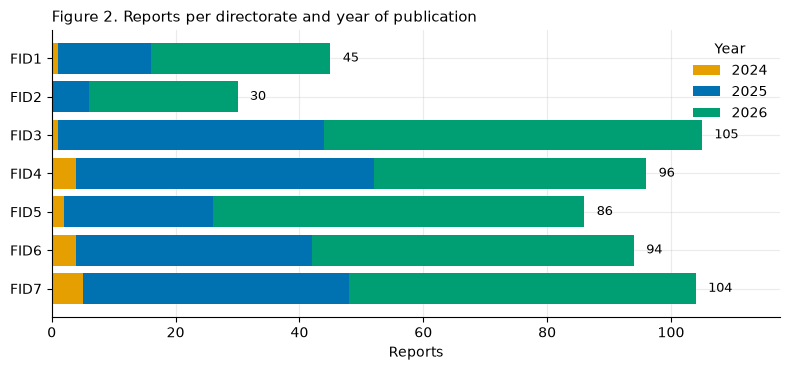

In [5]:
dir_year = pd.crosstab(meta_df["directorate_en"], meta_df["year"])
assert list(dir_year.index) == [f"FID{i}" for i in range(1, 8)]
assert dir_year.values.sum() == 560
display(dir_year.assign(total=dir_year.sum(axis=1)))

fig, ax = plt.subplots(figsize=(8, 3.8))
left = np.zeros(len(dir_year))
for yr, col in zip(dir_year.columns, [C_ORANGE, C_BLUE, C_GREEN]):
    ax.barh(dir_year.index, dir_year[yr].values, left=left, color=col, label=str(yr))
    left += dir_year[yr].values
for y, tot in enumerate(left):
    ax.text(tot + 2, y, str(int(tot)), va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Reports")
ax.set_title("Figure 2. Reports per directorate and year of publication", loc="left")
ax.legend(title="Year", frameon=False, loc="upper right")
ax.set_xlim(0, left.max() * 1.12)
fig.tight_layout()
fig.savefig(FIG_DIR / "F2_reports_per_directorate.png", bbox_inches="tight")
plt.show()

*Reading Figure 2.* Each bar is one directorate; its segments are the numbers of its reports by year of publication, and the number at the end is the total. The differences between the bars show the workload recorded in the register and are not a comparison of the directorates.

#### 2.2.6 Personal-data scan

**Question.** Do the texts contain personal data that must not be published?

**Logic.** The scan counts patterns that look like personal data. A count is a *candidate*: a ten-digit number that passes the checksum may be a number of a document, and a name after a role noun may be a place. For that reason the study publishes counts only and does not publish the texts or the matched strings.

**What the next cell does.** It counts, per pattern type, the reports with at least one hit and the total number of hits, and draws Figure 3 with the number of reports. No matched string is shown.

,pattern_type,reports_with_hits,total_matches
0,email,476,792
1,phone,126,148
2,person_name_after_role,74,139
3,egn_explicit_label,0,0
4,egn_checksum_candidate,2,2


Reports with at least one hit of any pattern: 504 of 560


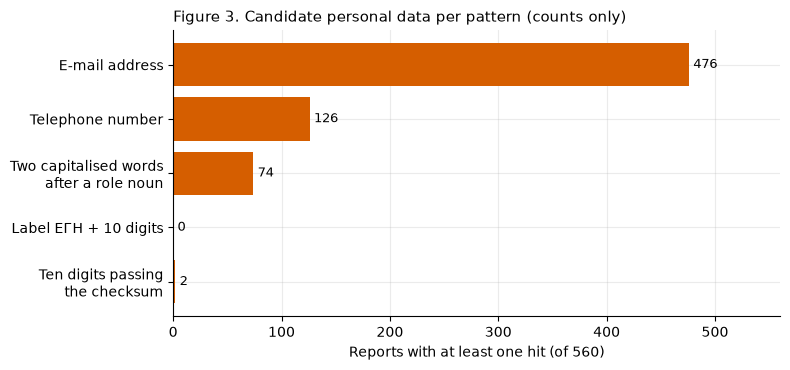

In [6]:
pii_summary = (
    pii_df.groupby("pattern_type")
    .agg(reports_with_hits=("report_key", "nunique"), total_matches=("match_count", "sum"))
    .reindex(["email", "phone", "person_name_after_role", "egn_explicit_label", "egn_checksum_candidate"])
    .fillna(0).astype(int).reset_index()
)
display(pii_summary)
print("Reports with at least one hit of any pattern:", pii_df["report_key"].nunique(), "of", len(meta_df))

_labels = {"email": "E-mail address", "phone": "Telephone number", "person_name_after_role": "Two capitalised words\nafter a role noun",
           "egn_explicit_label": "Label ЕГН + 10 digits", "egn_checksum_candidate": "Ten digits passing\nthe checksum"}
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh([_labels[p] for p in pii_summary["pattern_type"]], pii_summary["reports_with_hits"], color=C_VERMILION)
for y, v in enumerate(pii_summary["reports_with_hits"]):
    ax.text(v + 4, y, str(int(v)), va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Reports with at least one hit (of 560)")
ax.set_title("Figure 3. Candidate personal data per pattern (counts only)", loc="left")
ax.set_xlim(0, 560)
fig.tight_layout()
fig.savefig(FIG_DIR / "F3_pii_candidates.png", bbox_inches="tight")
plt.show()

*Reading Figure 3.* A bar is the number of reports in which the pattern was found at least once. A hit is a reason to keep the text out of the repository, not proof that a person is named. The counts above answer the question: e-mail addresses and telephone numbers are the most frequent hits and may belong to institutions, the label `ЕГН` was found in no report, and two reports contain a ten-digit number that passes the checksum. The texts are therefore not published.

#### 2.2.7 The classification table: rules, fetching and definition

##### Rules

**Question.** Which types of violation does the classifier distinguish, and how many findings does each type hold?

**Logic for a controller.** A finding is one assessed requirement in a report: the inspector either found that the requirement was breached (a violation) or recorded that it was met (no violation). Each finding is assigned to a **class** by the **action of the contracting authority**, not by the article of the law that it breaches. The index of a class is `section.class`. The 53 classes belong to 11 sections, from the choice of the award procedure (classifier section 1) to breaches of other statutes found during the checks (classifier section 11); classifier section 10 holds the findings on financial management and control, the ex-ante control and the double signature (Bulgaria, 2006a).

Each row of the table carries these attributes, which come from the text of the reports:

| Attribute | Values |
|---|---|
| `finding_no`, `school_name` | the number of the finding (a finding assigned to more than one class has more than one row) and the name of the school |
| `report_id`, `published`, `pages` | the path of the report (in the notation of Section 2.2.2), its date of publication and the pages of the report that the row refers to |
| `outcome` | `violation_with_act`, `violation_without_act`, `no_violation` |
| `act`, `act_state` | the number of the administrative violation act of the ADFI, and whether the number is given in the report, restored from the conclusion, unreadable, or there is no act |
| `law`, `provisions` | the statutes and the provisions cited by the inspector |
| `section`, `class_index`, `class_name` | the class of the finding |
| `basis_source` | the part of the report from which the class was read |
| `confidence` | `от самия извод` (from the conclusion itself), `от оценката в раздела` (from the assessment in the section), `от прочит` (from a reading of the text), `от заглавието на проверката` (from the title of the check) |

The classification is the author's. It was prepared from the text of the reports with rule-based text classification and is checked in the author's earlier study (Beluhov, 2026). The ADFI established the violations and issued the acts; the types are the author's.

##### Fetching the classification table

**What the next cell does.** The table is the one published by the earlier study, so the notebook does not carry a copy of its own. It downloads `data/adfi_classification.csv` from the repository `stem-collusion-npvu` at the fixed commit `c5feef1`, and compares the SHA-256 digest of the file with the expected one. If the file is already in `data/` with the right digest, nothing is downloaded. A wrong digest stops the notebook.

In [7]:
REF_SHA256 = "5b7aa7a71f373917276828d85856133a292ba37467939da734971c199dc04e0f"
CLS_FILE = DATA_DIR / "adfi_classification.csv"

if not (CLS_FILE.exists() and sha256_file(CLS_FILE) == REF_SHA256):
    with urllib.request.urlopen(REF_URL, timeout=60) as response:
        CLS_FILE.write_bytes(response.read())
assert sha256_file(CLS_FILE) == REF_SHA256, "The classification table differs from the published one"
print(f"{CLS_FILE.name}: {CLS_FILE.stat().st_size:,} bytes | SHA-256 {sha256_file(CLS_FILE)[:16]}... | source {REF_REPO}@{REF_COMMIT}")

cls_df = pd.read_csv(CLS_FILE, encoding="utf-8-sig", dtype=str)
print("Columns:", list(cls_df.columns))
print("Rows:", len(cls_df), "| reports:", cls_df["report_id"].nunique())

adfi_classification.csv: 977,933 bytes | SHA-256 5b7aa7a71f373917... | source beluhov/stem-collusion-npvu@c5feef1
Columns: ['finding_no', 'school_name', 'report_id', 'published', 'pages', 'outcome', 'act', 'act_state', 'law', 'provisions', 'section', 'class_index', 'class_name', 'basis_source', 'confidence']
Rows: 1824 | reports: 488


##### The classifier: definition of the 11 sections and 53 classes

**What the next cell does.** It defines the classifier as data: the 11 sections and the 53 classes with their Bulgarian and English names. This is the author's list of types. The cell after it joins the classification table to this definition and builds the table of classes with the number of rows of each class, and asserts that the totals are the ones that the study relies on.

The definition is needed because three classes (`1.05`, `5.04`, `10.04`) have no row in the table of the 560 reports. They exist in the classifier and have no row in these reports. Three more classes (`1.06`, `2.06`, `4.04`) have only rows with the outcome *no violation*.

In [8]:
CLASSIFIER_SECTIONS = [
    (1, "1. Избор на ред за възлагане", "1. Selection of Award Procedure"),
    (2, "2. Предмет и техническа спецификация", "2. Subject Matter and Technical Specification"),
    (3, "3. Изисквания към участниците", "3. Requirements for Tenderers"),
    (4, "4. Оферта и оценяване", "4. Tender Submission and Evaluation"),
    (5, "5. Откриване на поръчката", "5. Launching the Procurement"),
    (6, "6. Работа на комисията", "6. Evaluation Committee Work"),
    (7, "7. Сключване на договора", "7. Contract Conclusion"),
    (8, "8. Изпълнение на договора", "8. Contract Performance"),
    (9, "9. Публичност и досие", "9. Publicity and Procurement Dossier"),
    (10, "10. Финансово управление и контрол", "10. Financial Management and Control"),
    (11, "11. Нарушения по други закони, установени при проверка на поръчките", "11. Breaches of Other Statutes in Procurement Checks"),
]

CLASSIFIER_CLASSES = [
    ("1.01", "Разбиване на поръчки", "Splitting of procurements"),
    ("1.02", "Директно възлагане при стойност, която изисква обява или процедура", "Direct award at a value requiring a call or procedure"),
    ("1.03", "Покана до определени лица или пряко договаряне без законово основание", "Invitation to specific persons or direct negotiation without legal basis"),
    ("1.04", "Договаряне без изпратени доказателства до АОП", "Negotiation without evidence sent to PPA Agency"),
    ("1.05", "Строителство, възложено директно без писмен договор", "Works awarded directly without a written contract"),
    ("1.06", "Прогнозна стойност, определена без актуално проучване", "Estimated value determined without up-to-date market research"),
    ("2.01", "Пазарни консултации без оповестяване", "Market consultations without disclosure"),
    ("2.02", "Разнородни доставки в поръчка без обособени позиции", "Heterogeneous supplies in a procurement without lots"),
    ("2.03", "Разнородни доставки в една обособена позиция на разделена поръчка", "Heterogeneous supplies in a single lot of a divided procurement"),
    ("2.04", "Подправени спецификации – посочена търговска марка или модел", "Tailored specifications – brand or model specified"),
    ("2.05", "Пропуснати екологични изисквания към продуктите", "Omitted environmental requirements for products"),
    ("2.06", "Стандарт, изискан за доставяната стока", "Standard required for the supplied goods"),
    ("3.01", "Изискване за собствена сервизна база или система за поддръжка", "Requirement for own service base or support system"),
    ("3.02", "Сертификат за информационна сигурност или управление на услуги, изискан от участника в поръчка за доставка (ISO/IEC 27001, 27701, 20000-1)", "Information security or service management certificate required from the tenderer in a supply procurement (ISO/IEC 27001, 27701, 20000-1)"),
    ("3.03", "Сертификат за качество, околна среда или безопасност на труда, изискан от участника (ISO 9001, 14001, 45001)", "Quality, environmental, or occupational health and safety certificate required from the tenderer (ISO 9001, 14001, 45001)"),
    ("3.04", "Изисквания към екипа на участника", "Requirements for the tenderer's team"),
    ("3.05", "Изискване за опит в сходни дейности", "Requirement for experience in similar activities"),
    ("3.06", "Изискване за оборот", "Turnover requirement"),
    ("3.07", "Изискване за оторизация от производителя", "Requirement for manufacturer authorization"),
    ("3.08", "Изискване за регистрация, която не се дължи или е завишена", "Requirement for registration that is not due or is excessive"),
    ("3.09", "Оценка за устойчивост EcoVadis, изискана от участника", "EcoVadis sustainability rating required from the tenderer"),
    ("3.10", "Изискване за обучение от организация с одобрена от министъра програма", "Requirement for training by an organization with a minister-approved program"),
    ("3.11", "Стеснени доказателства за критерий за подбор", "Narrowed evidence for a selection criterion"),
    ("4.01", "Изисквания към съдържанието на техническото предложение (работна програма, стратегия, подход за управление на риска) като условие за допускане", "Requirements for the content of the technical proposal (work program, strategy, risk management approach) as a condition for admission"),
    ("4.02", "Незаконосъобразна методика за оценка", "Unlawful evaluation methodology"),
    ("4.03", "Пределни единични цени като условие за допускане", "Maximum unit prices as a condition for admission"),
    ("4.04", "Декларация по чл. 47, ал. 3 от ЗОП, изискана към офертата", "Declaration under Art. 47(3) PPA required with the tender"),
    ("4.05", "Проект или визуализация на стоката, изискани към офертата", "Design or visualization of the goods required with the tender"),
    ("5.01", "Непълно обявление или обява", "Incomplete contract notice or call"),
    ("5.02", "Незаконосъобразно определени гаранции в обявлението или проекта на договор", "Unlawfully determined guarantees in the contract notice or draft contract"),
    ("5.03", "Промяна на датата на отваряне без съобщение", "Change of opening date without notice"),
    ("5.04", "Срок на договора над 5 години без мотиви", "Contract duration over 5 years without reasons"),
    ("5.05", "Краен срок за оферти в неприсъствен ден", "Tender submission deadline on a non-working day"),
    ("6.01", "Назначаване и състав на комисията; неподадена в срок декларация за липса на конфликт на интереси", "Appointment and composition of the committee; conflict-of-interest declaration not submitted on time"),
    ("6.02", "Допускане, оценяване или класиране в отклонение от условията", "Admission, evaluation, or ranking in deviation from the conditions"),
    ("7.01", "Договор, сключен без документи или без изпълнено условие", "Contract concluded without documents or without a fulfilled condition"),
    ("7.02", "Договор, различен от проекта и от офертата", "Contract different from the draft and from the tender"),
    ("7.03", "Договор, сключен преди влизане в сила на решението за откриване", "Contract concluded before entry into force of the launch decision"),
    ("8.01", "Изменение на договор без основание", "Contract modification without legal basis"),
    ("9.01", "Неизпратено в срок обявление за възложена поръчка при процедура", "Award notice not sent on time in a procedure"),
    ("9.02", "Неизпратено в срок обявление за възложена поръчка при събиране на оферти с обява", "Award notice not sent on time in a call for tenders"),
    ("9.03", "Неизпратено в срок обявление за приключване или изменение на договор", "Contract completion or modification notice not sent on time"),
    ("9.04", "Непубликуван в срок договор или приложение към него", "Contract or annex not published on time"),
    ("9.05", "Непубликувани в срок протоколи и доклади на комисията", "Committee protocols and reports not published on time"),
    ("9.06", "Непубликувани в срок решение, обявление или обява, документация, покани или разяснения", "Decision, contract notice or call, documentation, invitations, or clarifications not published on time"),
    ("9.07", "Непълно досие на поръчката", "Incomplete procurement dossier"),
    ("10.01", "Задължение или плащане без предварителен контрол", "Commitment or payment without ex-ante control"),
    ("10.02", "Задължение или плащане без двоен подпис", "Commitment or payment without double signature"),
    ("10.03", "Невъведен ред за предварителен контрол", "Unestablished procedure for ex-ante control"),
    ("10.04", "Неосъществен предварителен контрол за законосъобразност на поръчка над прага", "Unperformed ex-ante control for legality of a procurement above the threshold"),
    ("11.01", "Неизпратено в срок уведомление за предстоящо плащане чрез ИС „Разплащания с публични средства“", "Upcoming payment notification not sent on time via IS Public Payments"),
    ("11.02", "Плащане без потвърждение от НАП и Агенция „Митници“", "Payment without confirmation from NRA and Customs Agency"),
    ("11.03", "Неизпратено в срок уведомление за сключен договор чрез ИС „Разплащания с публични средства“", "Concluded contract notification not sent on time via IS Public Payments"),
]

assert len(CLASSIFIER_SECTIONS) == 11 and len(CLASSIFIER_CLASSES) == 53
assert len({c[0] for c in CLASSIFIER_CLASSES}) == 53


**What the next cell does.** It joins the table to the definition, checks that every class name of the table is the classifier's own, counts the rows per class, writes `data/derived/classifier_classes.csv` and asserts the totals.

In [9]:
sec_en = {num: en for num, bg, en in CLASSIFIER_SECTIONS}
sec_bg = {num: bg for num, bg, en in CLASSIFIER_SECTIONS}
base = pd.DataFrame(CLASSIFIER_CLASSES, columns=["class_index", "class_bg", "class_en"])
base["section_no"] = base["class_index"].str.split(".").str[0].astype(int)
base["section_bg"] = base["section_no"].map(sec_bg)
base["section_en"] = base["section_no"].map(sec_en)

cls_df["is_violation"] = cls_df["outcome"].ne("no_violation")
names_ok = cls_df[["class_index", "class_name"]].drop_duplicates().merge(base, on="class_index", how="left")
assert (names_ok["class_name"] == names_ok["class_bg"]).all(), "A class name in the table differs from the classifier"
assert set(cls_df["section"]) <= set(sec_bg.values())

counts = (
    cls_df.groupby("class_index")
    .agg(rows_violation=("is_violation", "sum"), rows_total=("is_violation", "size"), reports=("report_id", "nunique"))
    .reset_index()
)
classes = base.merge(counts, on="class_index", how="left").fillna({"rows_violation": 0, "rows_total": 0, "reports": 0})
for c in ("rows_violation", "rows_total", "reports"):
    classes[c] = classes[c].astype(int)
classes["rows_no_violation"] = classes["rows_total"] - classes["rows_violation"]
classes = classes[["class_index", "section_no", "section_en", "class_en", "section_bg", "class_bg",
                   "rows_violation", "rows_no_violation", "rows_total", "reports"]]
classes.to_csv(DERIVED_DIR / "classifier_classes.csv", sep=";", index=False, encoding="utf-8", lineterminator="\n")

n_viol = int(classes["rows_violation"].sum())
n_noviol = int(classes["rows_no_violation"].sum())
assert (n_viol, n_noviol, n_viol + n_noviol) == (1203, 621, 1824)
assert (cls_df["outcome"] == "violation_with_act").sum() == 1148 and (cls_df["outcome"] == "violation_without_act").sum() == 55
assert int((classes["rows_total"] > 0).sum()) == 50
assert classes.loc[classes["rows_total"] == 0, "class_index"].tolist() == ["1.05", "5.04", "10.04"]
assert classes.loc[(classes["rows_total"] > 0) & (classes["rows_violation"] == 0), "class_index"].tolist() == ["1.06", "2.06", "4.04"]
assert cls_df["report_id"].nunique() == 488
_conf = pd.crosstab(cls_df["confidence"], cls_df["is_violation"])
assert _conf.loc["от самия извод"].tolist() == [393, 948] and _conf.loc["от оценката в раздела"].tolist() == [29, 188]
assert _conf.loc["от прочит"].tolist() == [176, 67] and _conf.loc["от заглавието на проверката"].tolist() == [23, 0]
print(f"Rows: {n_viol} violation + {n_noviol} no violation = {n_viol + n_noviol} | classes with rows: {int((classes['rows_total'] > 0).sum())} of 53")
display(classes[["class_index", "class_en", "rows_violation", "rows_no_violation", "rows_total", "reports"]])

Rows: 1203 violation + 621 no violation = 1824 | classes with rows: 50 of 53


,class_index,class_en,rows_violation,rows_no_violation,rows_total,reports
0,1.01,Splitting of procurements,10,4,14,14
1,1.02,Direct award at a value requiring a call or pr...,12,4,16,12
2,1.03,Invitation to specific persons or direct negot...,3,1,4,4
3,1.04,Negotiation without evidence sent to PPA Agency,2,0,2,2
4,1.05,Works awarded directly without a written contract,0,0,0,0
5,1.06,Estimated value determined without up-to-date ...,0,34,34,31
6,2.01,Market consultations without disclosure,7,44,51,48
7,2.02,Heterogeneous supplies in a procurement withou...,113,101,214,187
8,2.03,Heterogeneous supplies in a single lot of a di...,6,41,47,39
9,2.04,Tailored specifications – brand or model speci...,5,13,18,18


**Reading the table.** One line is one class of the classifier: its index, its English name (the Bulgarian name is in `data/derived/classifier_classes.csv`), the number of violation rows, of no-violation rows, of all rows, and the number of reports that contain at least one row of the class. The table is the complete, visible classifier of this study.

#### 2.2.8 Rows by section and by class

**Question.** How are the 1,824 rows distributed over the sections and the classes of the classifier?

**Logic.** Counting the rows shows what the classification holds before any hypothesis is tested. **This is a description of the table, not a test of H1a:** the test of Question 1 uses only the violation rows, orders the classes by size and cumulates the shares, and it belongs to the next part of the study.

**What the next cell does.** It draws Figure 4 (rows by section) with the table of the numbers above it. Figure 5 (rows by class) follows; a class with no row is marked `0`.

,section_no,section_en,rows_violation,rows_no_violation,rows_total
0,1,1. Selection of Award Procedure,27,43,70
1,2,2. Subject Matter and Technical Specification,162,226,388
2,3,3. Requirements for Tenderers,544,123,667
3,4,4. Tender Submission and Evaluation,197,68,265
4,5,5. Launching the Procurement,8,31,39
5,6,6. Evaluation Committee Work,4,75,79
6,7,7. Contract Conclusion,84,15,99
7,8,8. Contract Performance,2,1,3
8,9,9. Publicity and Procurement Dossier,125,29,154
9,10,10. Financial Management and Control,43,10,53


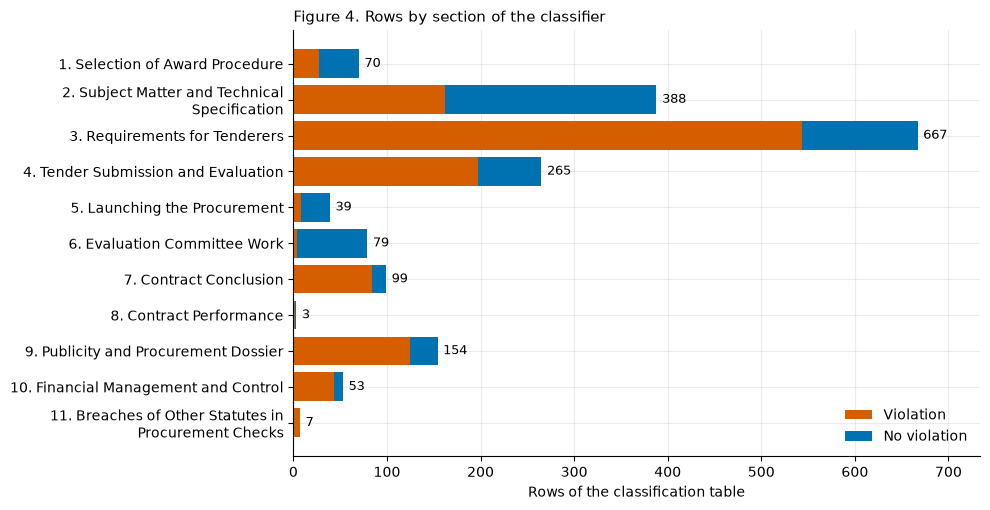

In [10]:
sec_tab = classes.groupby(["section_no", "section_en"])[["rows_violation", "rows_no_violation"]].sum().reset_index()
display(sec_tab.assign(rows_total=sec_tab["rows_violation"] + sec_tab["rows_no_violation"]))

fig, ax = plt.subplots(figsize=(10, 5.2))
labels = [textwrap.fill(s, 38) for s in sec_tab["section_en"]]
ax.barh(labels, sec_tab["rows_violation"], color=C_VERMILION, label="Violation")
ax.barh(labels, sec_tab["rows_no_violation"], left=sec_tab["rows_violation"], color=C_BLUE, label="No violation")
for y, (a, b) in enumerate(zip(sec_tab["rows_violation"], sec_tab["rows_no_violation"])):
    ax.text(a + b + 6, y, str(int(a + b)), va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Rows of the classification table")
ax.set_title("Figure 4. Rows by section of the classifier", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.set_xlim(0, (sec_tab["rows_violation"] + sec_tab["rows_no_violation"]).max() * 1.1)
fig.tight_layout()
fig.savefig(FIG_DIR / "F4_rows_by_section.png", bbox_inches="tight")
plt.show()

*Reading Figure 4.* Each bar is one section; its red part is the number of violation rows and its blue part the number of rows where the requirement was assessed as met. The number at the end is the total.

**What the next cell does.** It draws Figure 5, one bar for each of the 53 classes in the order of the classifier.

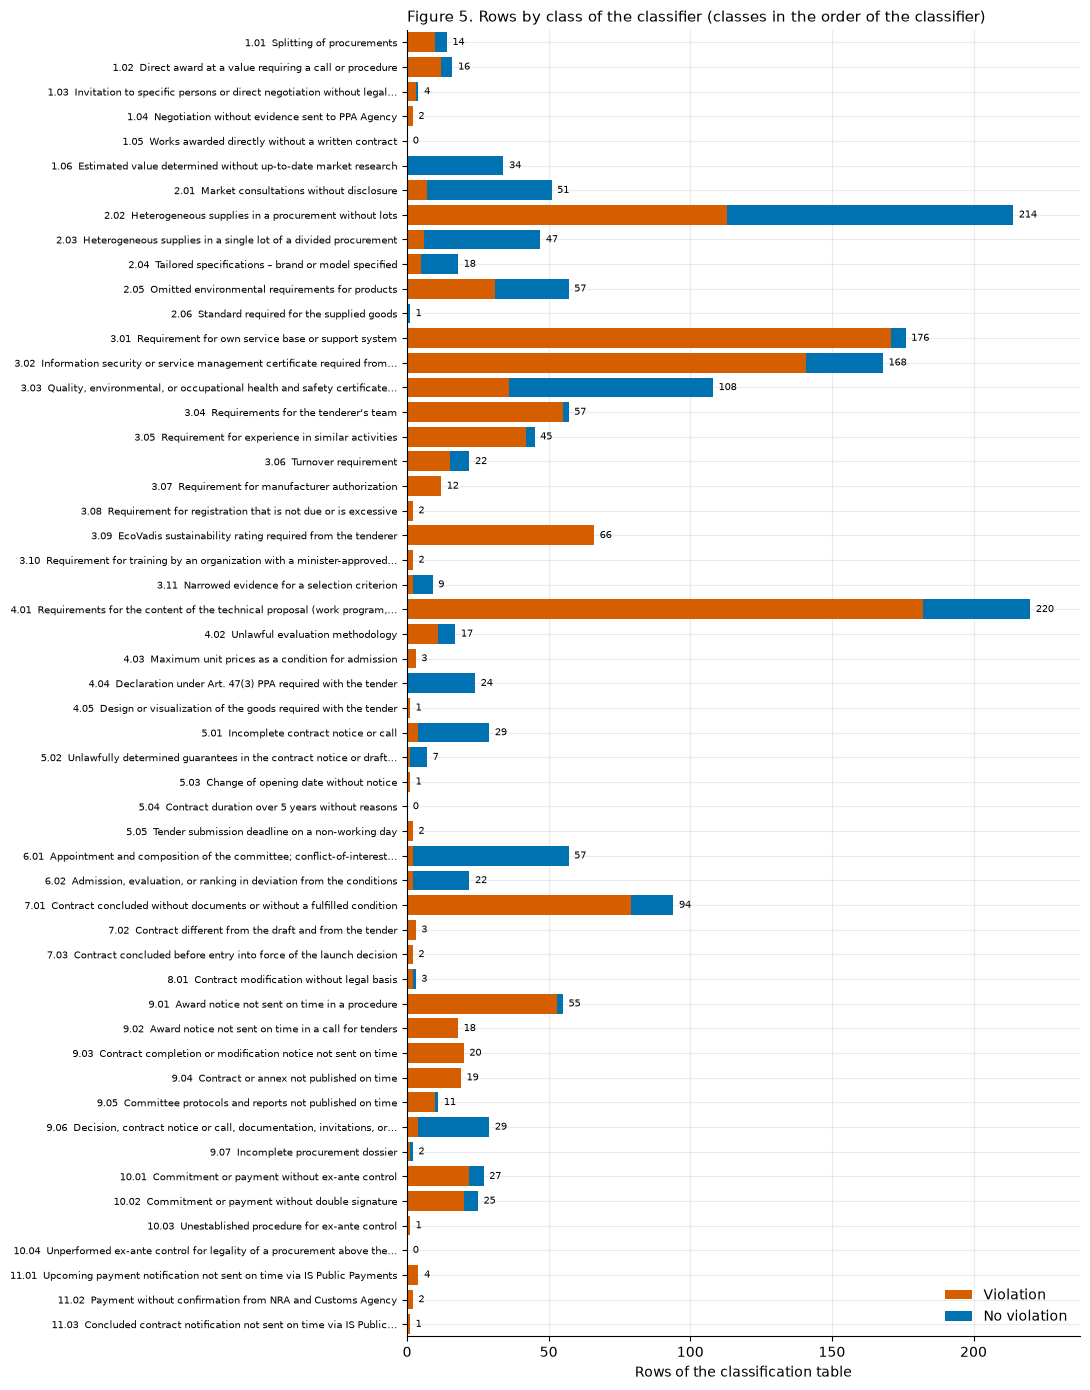

In [11]:
fig, ax = plt.subplots(figsize=(11, 14))
ylab = [f"{r.class_index}  " + textwrap.shorten(r.class_en, 70, placeholder="…") for r in classes.itertuples()]
ypos = np.arange(len(classes))
ax.barh(ypos, classes["rows_violation"], color=C_VERMILION, label="Violation")
ax.barh(ypos, classes["rows_no_violation"], left=classes["rows_violation"], color=C_BLUE, label="No violation")
for y, r in zip(ypos, classes.itertuples()):
    ax.text(r.rows_total + 2, y, str(r.rows_total), va="center", fontsize=7.5)
ax.set_yticks(ypos)
ax.set_yticklabels(ylab, fontsize=7.5)
ax.set_ylim(len(classes) - 0.5, -0.5)
ax.set_xlabel("Rows of the classification table")
ax.set_title("Figure 5. Rows by class of the classifier (classes in the order of the classifier)", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.set_xlim(0, classes["rows_total"].max() * 1.08)
fig.tight_layout()
fig.savefig(FIG_DIR / "F5_rows_by_class.png", bbox_inches="tight")
plt.show()

*Reading Figure 5.* Each bar is one of the 53 classes in the order of the classifier, not in the order of size. The red part is the number of violation rows, the blue part the number of rows assessed as met. A class with `0` has no row in these 560 reports.

#### 2.2.9 Reconciliation of the reports and the rows

**Question.** How many of the 560 reports have rows in the classification table, and how do the 1,824 rows divide by outcome?

**Logic.** Each of the 560 reports is either in the table (it has at least one finding) or not. Every row of the table must belong to a report of the register, so the keys of the table must be a subset of the keys of the metadata.

**What the next cell does.** It brings the report paths of the table to report keys, checks that all of them are in the metadata, and draws Figure 6: the reports with and without rows, and the rows by outcome.

Reports with rows: 488 | without rows: 72 | rows: 1824


,rows
outcome,
violation_with_act,1148
no_violation,621
violation_without_act,55


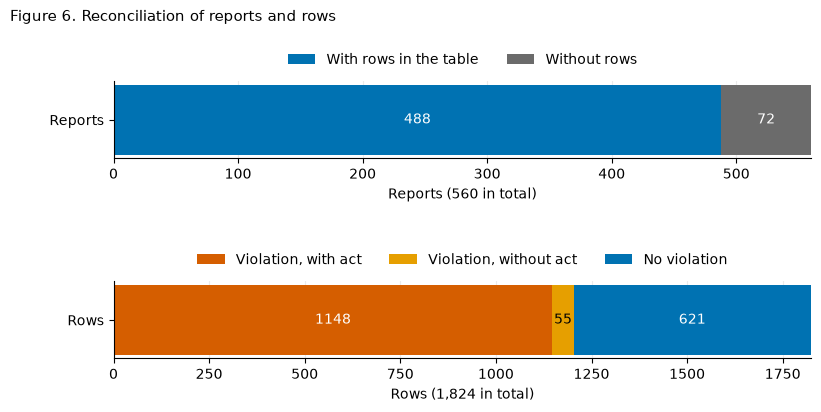

In [12]:
cls_df["report_key"] = cls_df["report_id"].map(normalize_report_key)
keys_in_table = set(cls_df["report_key"])
assert keys_in_table <= set(meta_df["report_key"]), "A report of the table is not in the register"
n_with, n_without = len(keys_in_table), len(meta_df) - len(keys_in_table)
assert (n_with, n_without) == (488, 72)
outcome_counts = cls_df["outcome"].value_counts()
print(f"Reports with rows: {n_with} | without rows: {n_without} | rows: {len(cls_df)}")
display(outcome_counts.rename("rows").to_frame())

fig, axes = plt.subplots(2, 1, figsize=(9, 3.6), gridspec_kw={"hspace": 1.6})
ax = axes[0]
ax.barh(["Reports"], [n_with], color=C_BLUE, label="With rows in the table")
ax.barh(["Reports"], [n_without], left=[n_with], color=C_GREY, label="Without rows")
ax.text(n_with / 2, 0, f"{n_with}", ha="center", va="center", color="white", fontsize=10)
ax.text(n_with + n_without / 2, 0, f"{n_without}", ha="center", va="center", color="white", fontsize=10)
ax.set_xlim(0, 560)
ax.set_xlabel("Reports (560 in total)")
ax.legend(frameon=False, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.02))
ax = axes[1]
left = 0
for key, col, lab in [("violation_with_act", C_VERMILION, "Violation, with act"), ("violation_without_act", C_ORANGE, "Violation, without act"),
                      ("no_violation", C_BLUE, "No violation")]:
    v = int(outcome_counts[key])
    ax.barh(["Rows"], [v], left=[left], color=col, label=lab)
    ax.text(left + v / 2, 0, str(v), ha="center", va="center", color="white" if key != "violation_without_act" else "black", fontsize=10)
    left += v
ax.set_xlim(0, len(cls_df))
ax.set_xlabel("Rows (1,824 in total)")
ax.legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Figure 6. Reconciliation of reports and rows", x=0.01, ha="left", y=1.08, fontsize=11)
fig.savefig(FIG_DIR / "F6_reconciliation.png", bbox_inches="tight")
plt.show()

*Reading Figure 6.* The upper bar divides the 560 reports into those with at least one row in the table and those without; the lower bar divides the 1,824 rows into violations with an act, violations without an act and findings of no violation. The classification covers the reports as the table gives them; 72 reports have no row in it, because they hold neither a finding nor a conclusion that the classifier could assign to a class. The two units of analysis behind these counts, the findings and the rows, are reconciled in Section 2.2.10.

#### 2.2.10 The two units of analysis: findings and rows

**Question.** How many findings and how many rows does the classification table hold, how many of them are violations and how many are conclusions of no violation, and do the numbers agree with one another and with the study that published the table?

**Logic for a controller.** The table has two units, and a count is correct only if it says which unit it counts. A **finding** is one assessed requirement of a report, with one number `finding_no`: either a violation or a conclusion that there is no violation. A **row** is one finding in one class of the classifier. A finding that carries several classes has several rows, so counting rows alone would count such a finding more than once, and the same holds for the administrative violation acts of the ADFI. The two units are therefore counted separately and tied together by two identities:

$$ N_{\text{rows}} = N_{\text{viol\_rows}} + N_{\text{noviol\_rows}}, \qquad N_{\text{findings}} = \lvert\{\text{finding\_no}\}_{\text{viol}}\rvert + \lvert\{\text{finding\_no}\}_{\text{noviol}}\rvert $$

where $N_{\text{rows}}$ is the number of rows of the table, $N_{\text{viol\_rows}}$ and $N_{\text{noviol\_rows}}$ are its violation rows and its no-violation rows, and $\lvert\{\text{finding\_no}\}_{\text{viol}}\rvert$ and $\lvert\{\text{finding\_no}\}_{\text{noviol}}\rvert$ are the numbers of distinct finding numbers among the violation rows and among the no-violation rows. The second identity holds only if no finding is at the same time a violation and a conclusion of no violation; the next cell asserts it.

**Comparison with the earlier study.** Nine of the numbers are published in the study that produced the table (Beluhov, 2026): the reports, the reports with rows and without rows, the rows, the findings, the violations with and without an act and the conclusions of no violation are in its Section 4.2.1 "Source Tables and Invariants", and the number of distinct act cells is in its Section 4.2.7 "Key Quantities of the Audit Records". For these nine numbers the notebook sets the published number beside the counted one. The study gives no other totals, no count by class and no count by level of confidence, so these numbers are only counted here.

**Assumptions and limits.**

- The key of a report is unique in the register, and every key of the table is a key of the register. The table does not have to hold every key: 72 reports have no row (Section 2.2.9).
- A finding has one outcome. If one finding number stood in both groups, the second identity would be false.
- The acts are counted in two ways. A cell of the column `act` may list several act numbers, so the number of distinct separate numbers (706) is larger than the number of distinct non-empty cells (644). The earlier study counts cells. A violation with an act whose number cannot be read in the report has an empty cell and is in neither count.
- The check shows that the table agrees with itself and, for the nine numbers, with the published study. It does not show that the classification is correct, and the reports are a sample of the inspections.

**What the next cell does.** It splits the table into violation rows and no-violation rows and counts the findings, the rows, the reports and the acts. It sets the nine published numbers beside the counted ones, counts the rows of each class and of each level of confidence, asserts the checks above and sets `reconciliation_ok`. It writes `data/derived/reconciliation_totals.csv` and `data/derived/reconciliation_summary.csv`; the columns `expected`, `diff` and `source` are filled only for the nine published numbers.

In [13]:
viol = cls_df[cls_df["is_violation"]]
noviol = cls_df[~cls_df["is_violation"]]
findings_viol = set(viol["finding_no"])
findings_noviol = set(noviol["finding_no"])
findings_by_outcome = viol.groupby("outcome")["finding_no"].nunique()
classes_per_finding = cls_df.groupby("finding_no")["class_index"].nunique()
act_cells = cls_df["act"].dropna().str.strip()
act_cells = act_cells[act_cells != ""]
act_numbers = {token for cell in act_cells for token in cell.split()}

CONFIDENCE_EN = {
    "от самия извод": "from the conclusion itself",
    "от оценката в раздела": "from the assessment in the section",
    "от прочит": "from a reading of the text",
    "от заглавието на проверката": "from the title of the check",
}
assert set(cls_df["confidence"]) == set(CONFIDENCE_EN)
SRC_INVARIANTS = "Beluhov (2026), Section 4.2.1"
SRC_QUANTITIES = "Beluhov (2026), Section 4.2.7"

metrics = [
    ("totals", "Reports", len(meta_df), 560, SRC_INVARIANTS),
    ("totals", "Reports with rows", cls_df["report_key"].nunique(), 488, SRC_INVARIANTS),
    ("totals", "Reports without rows", len(meta_df) - cls_df["report_key"].nunique(), 72, SRC_INVARIANTS),
    ("totals", "Reports with a violation", viol["report_key"].nunique(), None, None),
    ("totals", "Reports with a conclusion of no violation", noviol["report_key"].nunique(), None, None),
    ("totals", "Rows", len(cls_df), 1824, SRC_INVARIANTS),
    ("totals", "Violation rows", len(viol), None, None),
    ("totals", "No-violation rows", len(noviol), None, None),
    ("totals", "Findings", cls_df["finding_no"].nunique(), 1373, SRC_INVARIANTS),
    ("totals", "Findings in more than one class", int((classes_per_finding > 1).sum()), None, None),
    ("totals", "Violations", len(findings_viol), None, None),
    ("totals", "Violations with an act", int(findings_by_outcome["violation_with_act"]), 739, SRC_INVARIANTS),
    ("totals", "Violations without an act", int(findings_by_outcome["violation_without_act"]), 45, SRC_INVARIANTS),
    ("totals", "Conclusions of no violation", len(findings_noviol), 589, SRC_INVARIANTS),
    ("totals", "Distinct act cells", len(set(act_cells)), 644, SRC_QUANTITIES),
    ("totals", "Distinct act numbers", len(act_numbers), None, None),
]
for conf_bg, conf_en in CONFIDENCE_EN.items():
    metrics.append(("confidence / violation rows", conf_en, int((viol["confidence"] == conf_bg).sum()), None, None))
for conf_bg, conf_en in CONFIDENCE_EN.items():
    metrics.append(("confidence / no-violation rows", conf_en, int((noviol["confidence"] == conf_bg).sum()), None, None))

totals = pd.DataFrame(metrics, columns=["table", "metric", "observed", "expected", "source"])
totals["observed"] = totals["observed"].astype(int)
totals["expected"] = totals["expected"].astype("Int64")
totals["diff"] = totals["observed"] - totals["expected"]
totals = totals[["table", "metric", "observed", "expected", "diff", "source"]]
assert int(totals["expected"].notna().sum()) == 9

summary = classes[["class_index", "class_en"]].copy()
summary["observed_viol_rows"] = summary["class_index"].map(viol["class_index"].value_counts()).fillna(0).astype(int)
summary["observed_noviol_rows"] = summary["class_index"].map(noviol["class_index"].value_counts()).fillna(0).astype(int)
summary["zero_count_class"] = ((summary["observed_viol_rows"] + summary["observed_noviol_rows"]) == 0).astype(int)

checks = {
    "the key of a report is unique in the register": bool(meta_df["report_key"].is_unique),
    "every key of the table is a key of the register": set(cls_df["report_key"]) <= set(meta_df["report_key"]),
    "no finding is both a violation and a conclusion of no violation": not (findings_viol & findings_noviol),
    "the findings split into violations and conclusions of no violation": len(findings_viol) + len(findings_noviol) == cls_df["finding_no"].nunique(),
    "a violation is either with an act or without an act": int(findings_by_outcome.sum()) == len(findings_viol),
    "the rows split into violation rows and no-violation rows": len(viol) + len(noviol) == len(cls_df),
    "every class index of the table is one of the 53 classes": set(cls_df["class_index"]) <= set(classes["class_index"]),
    "the section of a row is the section of its class index": bool((cls_df["section"] == cls_df["class_index"].str.split(".").str[0].astype(int).map(sec_bg)).all()),
    "the rows of the 53 classes add up to the rows of the table": int(summary[["observed_viol_rows", "observed_noviol_rows"]].sum().sum()) == len(cls_df),
    "no act number stands outside the violations with an act": bool((cls_df.loc[cls_df["outcome"] != "violation_with_act", "act"].fillna("").str.strip() == "").all()),
    "the nine published numbers equal the counted ones": bool((totals["diff"].dropna() == 0).all()),
}
checks_df = pd.Series(checks, name="passed").rename_axis("check").reset_index()
reconciliation_ok = bool(checks_df["passed"].all())
assert reconciliation_ok, "The reconciliation of the findings and the rows failed"

totals.to_csv(DERIVED_DIR / "reconciliation_totals.csv", sep=";", index=False, encoding="utf-8", lineterminator="\n")
summary.to_csv(DERIVED_DIR / "reconciliation_summary.csv", sep=";", index=False, encoding="utf-8", lineterminator="\n")

print(f"reconciliation_ok = {reconciliation_ok} | findings: {len(findings_viol) + len(findings_noviol)} | rows: {len(cls_df)}")
display(checks_df)
display(totals)
print("Classes without a row:", summary.loc[summary["zero_count_class"] == 1, "class_index"].tolist())

reconciliation_ok = True | findings: 1373 | rows: 1824


,check,passed
0,the key of a report is unique in the register,True
1,every key of the table is a key of the register,True
2,no finding is both a violation and a conclusio...,True
3,the findings split into violations and conclus...,True
4,a violation is either with an act or without a...,True
5,the rows split into violation rows and no-viol...,True
6,every class index of the table is one of the 5...,True
7,the section of a row is the section of its cla...,True
8,the rows of the 53 classes add up to the rows ...,True
9,no act number stands outside the violations wi...,True


,table,metric,observed,expected,diff,source
0,totals,Reports,560,560,0,"Beluhov (2026), Section 4.2.1"
1,totals,Reports with rows,488,488,0,"Beluhov (2026), Section 4.2.1"
2,totals,Reports without rows,72,72,0,"Beluhov (2026), Section 4.2.1"
3,totals,Reports with a violation,410,<NA>,<NA>,NaN
4,totals,Reports with a conclusion of no violation,287,<NA>,<NA>,NaN
5,totals,Rows,1824,1824,0,"Beluhov (2026), Section 4.2.1"
6,totals,Violation rows,1203,<NA>,<NA>,NaN
7,totals,No-violation rows,621,<NA>,<NA>,NaN
8,totals,Findings,1373,1373,0,"Beluhov (2026), Section 4.2.1"
9,totals,Findings in more than one class,229,<NA>,<NA>,NaN


Classes without a row: ['1.05', '5.04', '10.04']


**Reading the tables.** The first table lists the checks; every one must be `True`, and `reconciliation_ok` is `True` only then. The second table is `data/derived/reconciliation_totals.csv`: `observed` is counted from the classification table, `expected` is the number published in the earlier study (Beluhov, 2026) with its `source`, and `diff` is `observed` minus `expected`. An empty `expected` means that the earlier study does not give the number, so it is only counted here. The rows of each of the 53 classes are in `data/derived/reconciliation_summary.csv`; the classes without a row are listed under the tables.

**What the next cell does.** It takes from the table one finding that carries three classes and one finding that has several rows in the same class, and shows their rows. They are the two cases in which the number of rows differs from the number of findings.

In [14]:
EXAMPLE_CLASSES = 3
multi_class = classes_per_finding[classes_per_finding == EXAMPLE_CLASSES]
example_multi = sorted(multi_class.index, key=int)[0]
same_class_rows = cls_df.groupby(["finding_no", "class_index"]).size()
same_class_rows = same_class_rows[same_class_rows > 1]
example_same = sorted({finding for finding, _ in same_class_rows.index}, key=int)[0]
shown = ["finding_no", "report_id", "class_index", "outcome", "provisions"]
print(f"Finding {example_multi}: {EXAMPLE_CLASSES} classes, {int((cls_df['finding_no'] == example_multi).sum())} rows")
display(cls_df.loc[cls_df["finding_no"] == example_multi, shown])
print(f"Finding {example_same}: several rows in one class")
display(cls_df.loc[cls_df["finding_no"] == example_same, shown])

Finding 63: 3 classes, 3 rows


,finding_no,report_id,class_index,outcome,provisions
68,63,2025/06/ДИД3-ПЛ-12-[1].md,2.02,violation_with_act,"чл. 2, ал. 2 от ЗОП"
69,63,2025/06/ДИД3-ПЛ-12-[1].md,3.02,violation_with_act,"чл. 2, ал. 2 от ЗОП"
70,63,2025/06/ДИД3-ПЛ-12-[1].md,3.03,violation_with_act,"чл. 2, ал. 2 от ЗОП"


Finding 1128: several rows in one class


,finding_no,report_id,class_index,outcome,provisions
1568,1128,2026/04/ДИД3-ВД-3-[1].md,2.02,no_violation,"чл. 2, ал. 2 от ЗОП"
1569,1128,2026/04/ДИД3-ВД-3-[1].md,2.02,no_violation,"чл. 49, ал. 1 от ЗОП"


*Reading the examples.* In the first finding each row has a different class, so the finding is one violation (or one conclusion) but has as many rows as classes. In the second finding all rows are in the same class and differ in the provisions that they cite; the finding is again one, and the rows must not be read as separate findings.

#### 2.2.11 Manifest of the data files

**What the next cell does.** It writes `data/MANIFEST.csv` with the size and the SHA-256 digest of every table and figure of the study, together with the source of each file and the date. Anyone can recompute the digests to check that a file has not been changed.

In [15]:
SOURCES = {
    "data/adfi_classification.csv": f"Fetched from {REF_REPO} at commit {REF_COMMIT} (SHA-256 checked)",
    "data/adfi_reports_meta.csv": "Prepared when the data were prepared (Section 2.2.4) from the register and the texts of the 560 reports",
    "data/derived/pii_scan.csv": "Prepared when the data were prepared (Sections 2.2.3 and 2.2.4): counts of candidate personal data per report",
    "data/derived/classifier_classes.csv": "Built in Section 2.2.7 from the classifier definition and the classification table",
}
manifest_files = sorted([*DATA_DIR.glob("*.csv"), *DERIVED_DIR.glob("*.csv"), *FIG_DIR.glob("*.png")])
manifest_files = [p for p in manifest_files if p.name != "MANIFEST.csv"]
with open(DATA_DIR / "MANIFEST.csv", "w", encoding="utf-8", newline="") as f:
    w = csv.writer(f, delimiter=";", lineterminator="\n")
    w.writerow(["file", "size_bytes", "sha256", "source", "date"])
    for p in manifest_files:
        rel = p.relative_to(ROOT).as_posix()
        src = SOURCES.get(rel, "Figure drawn by this notebook" if rel.startswith("fig/") else "Table written by this notebook")
        w.writerow([rel, p.stat().st_size, sha256_file(p), src, BUILD_DATE])
manifest = pd.read_csv(DATA_DIR / "MANIFEST.csv", sep=";")
display(manifest[["file", "size_bytes", "source"]])

,file,size_bytes,source
0,data/adfi_classification.csv,977933,Fetched from beluhov/stem-collusion-npvu at co...
1,data/adfi_reports_meta.csv,215023,Prepared when the data were prepared (Section ...
2,data/derived/classifier_classes.csv,14491,Built in Section 2.2.7 from the classifier def...
3,data/derived/pii_scan.csv,26184,Prepared when the data were prepared (Sections...
4,data/derived/reconciliation_summary.csv,3802,Table written by this notebook
5,data/derived/reconciliation_totals.csv,1407,Table written by this notebook
6,fig/F1_reports_per_month.png,132004,Figure drawn by this notebook
7,fig/F2_reports_per_directorate.png,73280,Figure drawn by this notebook
8,fig/F3_pii_candidates.png,90892,Figure drawn by this notebook
9,fig/F4_rows_by_section.png,191082,Figure drawn by this notebook


## References

1. **ADFI (2026)**. *Public Register of Reports from Public Financial Inspections Conducted under Art. 17 of the Public Financial Inspection Act*. Sofia: Public Financial Inspection Agency. [online] Available at: https://www.adfi.minfin.bg/bg/34 [Accessed: 1 November 2026].

2. **Beluhov, V. (2026)**. *Fiscal Exposure and Integrity Risk in School Public Procurement: Forensic Econometric and Network Analysis of the Bulgarian School STEM Programme (BG-RRP-1.015)*. [online] Available at: https://github.com/beluhov/stem-collusion-npvu [Accessed: 15 November 2026].

3. **Benjamini, Y. and Hochberg, Y. (1995)**. 'Controlling the false discovery rate: a practical and powerful approach to multiple testing', *Journal of the Royal Statistical Society: Series B (Methodological)*, 57(1), pp. 289–300. doi: [10.1111/j.2517-6161.1995.tb02031.x](https://doi.org/10.1111/j.2517-6161.1995.tb02031.x).

4. **Bulgaria (2006a)**. *Financial Management and Control in the Public Sector Act* (Закон за финансовото управление и контрол в публичния сектор). State Gazette, No. 21, 10 March 2006.

5. **Bulgaria (2006b)**. *Public Financial Inspection Act* (Закон за държавната финансова инспекция). State Gazette, No. 33, 21 April 2006.

6. **Bulgaria (2016)**. *Public Procurement Act* (Закон за обществените поръчки). State Gazette, No. 13, 16 February 2016.

7. **Cohen, J. (1960)**. 'A coefficient of agreement for nominal scales', *Educational and Psychological Measurement*, 20(1), pp. 37–46. doi: [10.1177/001316446002000104](https://doi.org/10.1177/001316446002000104).

8. **Cramér, H. (1946)**. *Mathematical Methods of Statistics*. Princeton, NJ: Princeton University Press, p. 282. [online] Available at: https://archive.org/details/in.ernet.dli.2015.223699 [Accessed: 15 November 2026].

9. **Efron, B. and Tibshirani, R.J. (1994)**. *An Introduction to the Bootstrap*. Chapman and Hall/CRC. doi: [10.1201/9780429246593](https://doi.org/10.1201/9780429246593).

10. **Pearson, K. (1900)**. 'On the criterion that a given system of deviations from the probable in the case of a correlated system of variables is such that it can be reasonably supposed to have arisen from random sampling', *The London, Edinburgh, and Dublin Philosophical Magazine and Journal of Science*, Series 5, 50(302), pp. 157–175. doi: [10.1080/14786440009463897](https://doi.org/10.1080/14786440009463897).

11. **Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M. and Duchesnay, É. (2011)**. 'Scikit-learn: machine learning in Python', *Journal of Machine Learning Research*, 12, pp. 2825–2830. [online] Available at: https://jmlr.org/papers/v12/pedregosa11a.html [Accessed: 15 November 2026].

12. **Phipson, B. and Smyth, G.K. (2010)**. 'Permutation P-values should never be zero: calculating exact P-values when permutations are randomly drawn', *Statistical Applications in Genetics and Molecular Biology*, 9(1), Article 39. doi: [10.2202/1544-6115.1585](https://doi.org/10.2202/1544-6115.1585).

13. **Salton, G. and Buckley, C. (1988)**. 'Term-weighting approaches in automatic text retrieval', *Information Processing & Management*, 24(5), pp. 513–523. doi: [10.1016/0306-4573(88)90021-0](https://doi.org/10.1016/0306-4573(88)90021-0).

14. **Wilson, E.B. (1927)**. 'Probable inference, the law of succession, and statistical inference', *Journal of the American Statistical Association*, 22(158), pp. 209–212. doi: [10.1080/01621459.1927.10502953](https://doi.org/10.1080/01621459.1927.10502953).